# 🎙️ 내 목소리로 배우는 PCM과 디지털 전송

| 구분 | 내용 |
|---|---|
| 학습 목표 | ① 아날로그 음성을 PCM(표본화 → 양자화 → 부호화)으로 디지털화하는 과정을 그래프로 확인한다 ② 디지털 신호를 암호화·전송·수신·복호화하는 과정을 이해한다 ③ 복원된 소리를 직접 들으며 각 단계의 영향(비트 수, 표본화 주파수, 잡음, 암호 키)을 체험한다 |
| 준비물 | 내 목소리 음성 파일(wav, mp3, m4a 등) 또는 노트북 마이크 |
| 진행 방법 | 위에서부터 셀을 순서대로 실행(`Shift + Enter`)하세요. 각 단계의 **설정값(대문자 변수)** 을 바꿔 다시 실행하며 결과를 비교합니다. |

### 전체 흐름
```text
[송신측]  음성 ─▶ ① 원 신호 ─▶ ② 표본화 ─▶ ③ 양자화 ─▶ ④ 부호화 ─▶ ⑤ 암호화 ─▶ ⑥ 선로 부호화
                                                                                    │
                                                                              전송 채널 (잡음)
                                                                                    │
[수신측]  소리 ◀─ ⑨ D/A 복원 ◀─ ⑧ 복호화(암호 해제 + PCM 복호) ◀─ ⑦ 비트 판정 ◀───────┘
```

---
# 0. 환경 설정
필요한 라이브러리를 불러오고, 그래프에 한글이 보이도록 폰트를 설정합니다. (처음 한 번만 실행)

In [1]:
import os, sys, glob, subprocess, hashlib, base64
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from scipy import signal
from scipy.io import wavfile
from scipy.special import erfc

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# 한글 폰트 설치 및 등록
if IN_COLAB and not glob.glob("/usr/share/fonts/truetype/nanum/NanumGothic.ttf"):
    subprocess.run("apt-get -qq -y install fonts-nanum > /dev/null", shell=True)
font_files = (glob.glob("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")
              + glob.glob("/usr/share/fonts/**/NotoSansCJK*-Regular.ttc", recursive=True))
if font_files:
    fm.fontManager.addfont(font_files[0])
    plt.rc("font", family=fm.FontProperties(fname=font_files[0]).get_name())

# 그래프 기본 스타일 (흑백 위주)
plt.rcParams.update({
    "axes.unicode_minus": False, "figure.figsize": (10, 3.2), "figure.dpi": 100,
    "axes.grid": True, "grid.color": "#dddddd", "axes.prop_cycle": plt.cycler(color=["black", "gray", "darkgray"]),
})

def play(x, fs, label=""):
    """소리 재생 플레이어 표시"""
    print(f"[소리 재생] {label}")
    try:
        from IPython.display import Audio, display
        display(Audio(np.asarray(x, dtype=float), rate=int(fs)))
    except ImportError:
        pass

def spectrum(x, fs):
    """주파수 스펙트럼 (최대값 기준 dB)"""
    X = np.abs(np.fft.rfft(x * np.hanning(len(x)))) + 1e-12
    f = np.fft.rfftfreq(len(x), 1 / fs)
    return f, 20 * np.log10(X / X.max())

print("환경 설정 완료 / Colab 환경:", IN_COLAB)

환경 설정 완료 / Colab 환경: True


---
# 1. 내 목소리 준비하기

`SOURCE` 값을 골라 실행하세요.

| `SOURCE` | 동작 |
|---|---|
| `"upload"` | 파일 선택 창이 뜨면 내 음성 파일(wav, mp3, m4a 등)을 올립니다. |
| `"record"` | 브라우저 마이크로 `RECORD_SEC` 초 동안 바로 녹음합니다. (마이크 권한 허용 필요) |
| `"sample"` | 마이크나 파일이 없을 때 쓰는 합성 모음 음성(아-에-이-오-우)입니다. |

> 컴퓨터 안에서 소리는 이미 디지털이지만, 이 실습에서는 **44,100 Hz 로 촘촘하게 저장된 음성을 "아날로그 신호"로 간주**하고 PCM 과정을 처음부터 다시 밟아 봅니다.

In [2]:
SOURCE = "upload"      # "upload" | "record" | "sample"
RECORD_SEC = 4         # 녹음 시간(초)
FS_ANALOG = 44100      # '아날로그'로 간주할 고해상도 샘플링 주파수(Hz)
MAX_SEC = 4            # 실습에 사용할 최대 길이(초)

In [3]:
def to_wav(src, dst="voice.wav"):
    """어떤 음성 파일이든 모노 44.1 kHz wav 로 변환해 읽기"""
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", src,
                    "-ac", "1", "-ar", str(FS_ANALOG), dst], check=True)
    _, data = wavfile.read(dst)
    return data

RECORD_JS = """
const sleep = t => new Promise(r => setTimeout(r, t));
const toB64 = blob => new Promise(res => { const rd = new FileReader();
  rd.onloadend = () => res(rd.result); rd.readAsDataURL(blob); });
var record = async (sec) => {
  const stream = await navigator.mediaDevices.getUserMedia({audio: true});
  const rec = new MediaRecorder(stream); const chunks = [];
  rec.ondataavailable = e => chunks.push(e.data);
  rec.start(); await sleep(sec * 1000); rec.stop();
  await new Promise(r => rec.onstop = r);
  stream.getTracks().forEach(t => t.stop());
  return await toB64(new Blob(chunks));
}
"""

def record(sec):
    """Colab 브라우저 마이크로 녹음"""
    from IPython.display import Javascript, display
    from google.colab.output import eval_js
    display(Javascript(RECORD_JS))
    print(f"{sec}초 동안 녹음합니다. 지금 말씀하세요...")
    data = eval_js(f"record({sec})")
    with open("rec.webm", "wb") as f:
        f.write(base64.b64decode(data.split(",")[1]))
    print("녹음 완료")
    return to_wav("rec.webm")

def sample_voice(sec=3.0, fs=FS_ANALOG):
    """합성 모음 음성 '아-에-이-오-우' (성대 펄스 + 포먼트 공명)"""
    t = np.arange(int(sec * fs)) / fs
    f0 = 140 + 20 * np.sin(2 * np.pi * 0.6 * t) + 4 * np.sin(2 * np.pi * 5.5 * t)   # 음높이 + 떨림
    pulses = np.diff(np.floor(np.cumsum(f0) / fs), prepend=0)                      # 성대 진동 펄스
    src = signal.lfilter([1], [1, -0.95], pulses)
    vowels = [(800, 1200, 2500), (500, 1900, 2500), (300, 2300, 3000), (500, 900, 2400), (330, 800, 2300)]
    seg = len(t) // len(vowels)
    out = []
    for k, formants in enumerate(vowels):
        y = src[k * seg:(k + 1) * seg]
        for F in formants:                                   # 포먼트(공명 주파수) 필터
            r = np.exp(-np.pi * 90 / fs)
            y = signal.lfilter([1 - r], [1, -2 * r * np.cos(2 * np.pi * F / fs), r * r], y)
        env = np.sin(np.linspace(0, np.pi, len(y))) ** 0.6   # 음절 크기 변화
        out.append(y * env)
    return np.concatenate(out)

# ── 음성 불러오기 ──
if SOURCE == "upload" and IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    x = to_wav(next(iter(uploaded)))
elif SOURCE == "record" and IN_COLAB:
    x = record(RECORD_SEC)
else:
    if SOURCE != "sample":
        print("Colab 환경이 아니어서 합성 예제 음성을 사용합니다.")
    x = sample_voice()

# ── 정리: 모노, 정규화, 앞 무음 제거, 길이 제한 ──
x = np.asarray(x, dtype=float)
if x.ndim > 1:
    x = x.mean(axis=1)
x = x / (np.abs(x).max() + 1e-12)
start = int(np.argmax(np.abs(x) > 0.05))
x = x[start:start + MAX_SEC * FS_ANALOG]
x = 0.95 * x / np.abs(x).max()
t = np.arange(len(x)) / FS_ANALOG

# 확대해서 볼 10 ms 구간(소리가 가장 큰 곳) 자동 선택
ZOOM = int(0.010 * FS_ANALOG)
z0 = int(np.argmax(np.convolve(x ** 2, np.ones(ZOOM), "valid")))
z1 = z0 + ZOOM

print(f"길이 {len(x) / FS_ANALOG:.2f}초, 표본 {len(x):,}개 (FS_ANALOG = {FS_ANALOG:,} Hz)")
play(x, FS_ANALOG, "원본 음성")

Saving 음성 261019_131612.m4a to 음성 261019_131612.m4a
길이 4.00초, 표본 176,400개 (FS_ANALOG = 44,100 Hz)
[소리 재생] 원본 음성


---
# Part A. PCM — 아날로그 음성을 디지털로

**PCM(Pulse Code Modulation, 펄스 부호 변조)** 은 세 단계로 이루어집니다.

| 단계 | 하는 일 | 결정하는 값 |
|---|---|---|
| 표본화 (Sampling) | 일정한 시간 간격으로 값을 뽑는다 (시간을 띄엄띄엄) | 표본화 주파수 `FS` |
| 양자화 (Quantization) | 뽑은 값을 정해진 단계 중 가장 가까운 값으로 반올림한다 (크기를 띄엄띄엄) | 비트 수 `N_BITS` |
| 부호화 (Encoding) | 단계 번호를 2진수(0과 1)로 바꾼다 | 비트율 = `FS × N_BITS` |

## ① 원 신호 (아날로그)
전체 파형, 소리가 가장 큰 10 ms 확대 구간, 주파수 스펙트럼을 봅니다.

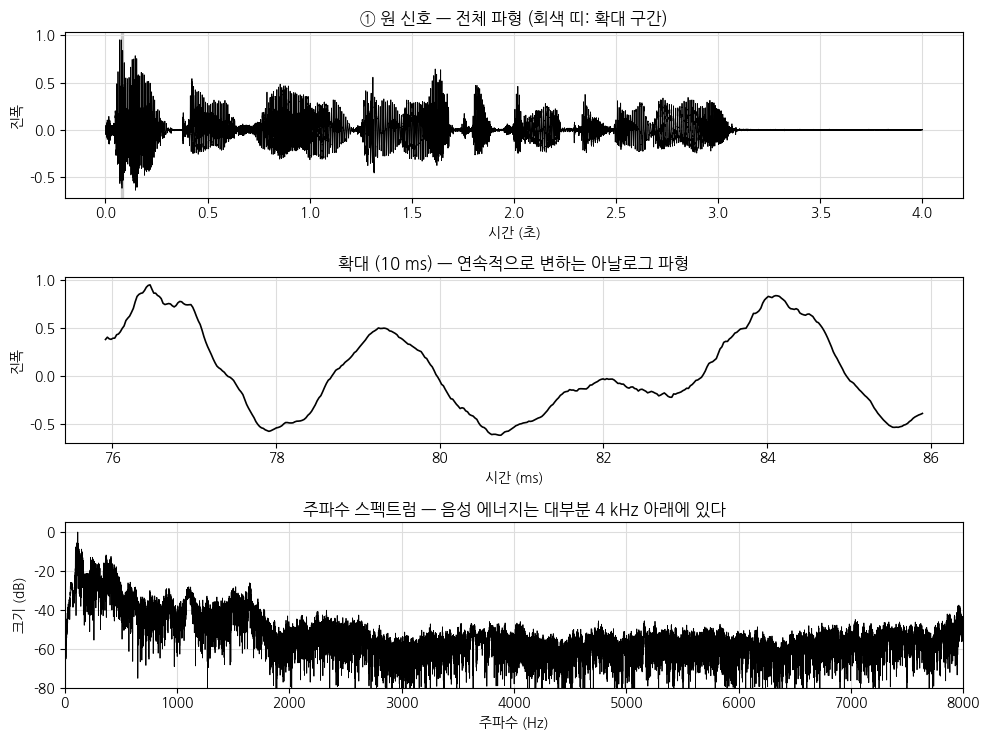

In [4]:
fig, ax = plt.subplots(3, 1, figsize=(10, 7.5))

ax[0].plot(t, x, lw=0.6)
ax[0].axvspan(t[z0], t[z1], color="gray", alpha=0.3)
ax[0].set(title="① 원 신호 — 전체 파형 (회색 띠: 확대 구간)", xlabel="시간 (초)", ylabel="진폭")

ax[1].plot(t[z0:z1] * 1000, x[z0:z1], lw=1.2)
ax[1].set(title="확대 (10 ms) — 연속적으로 변하는 아날로그 파형", xlabel="시간 (ms)", ylabel="진폭")

f, X = spectrum(x, FS_ANALOG)
ax[2].plot(f, X, lw=0.6)
ax[2].set(title="주파수 스펙트럼 — 음성 에너지는 대부분 4 kHz 아래에 있다", xlabel="주파수 (Hz)", ylabel="크기 (dB)",
          xlim=(0, 8000), ylim=(-80, 5))
plt.tight_layout()
plt.show()

## ② 표본화 (Sampling)

**나이퀴스트 표본화 정리** : 신호에 들어 있는 가장 높은 주파수의 **2배 이상**으로 표본화해야 원래 신호를 복원할 수 있습니다.

- 전화망(G.711)은 음성을 **300 ~ 3,400 Hz** 로 제한하고 **8,000 Hz** 로 표본화합니다. (8,000 ≥ 2 × 3,400)
- 표본화하기 전에 **저역통과필터(LPF, 앨리어싱 방지 필터)** 로 `FS/2` 보다 높은 주파수를 먼저 잘라 냅니다.

표본화 주파수 8,000 Hz → 표본 간격 125 μs, 표본 수 32,000개
원 신호 표본 176,400개 → 32,000개 (5.5배 감소)


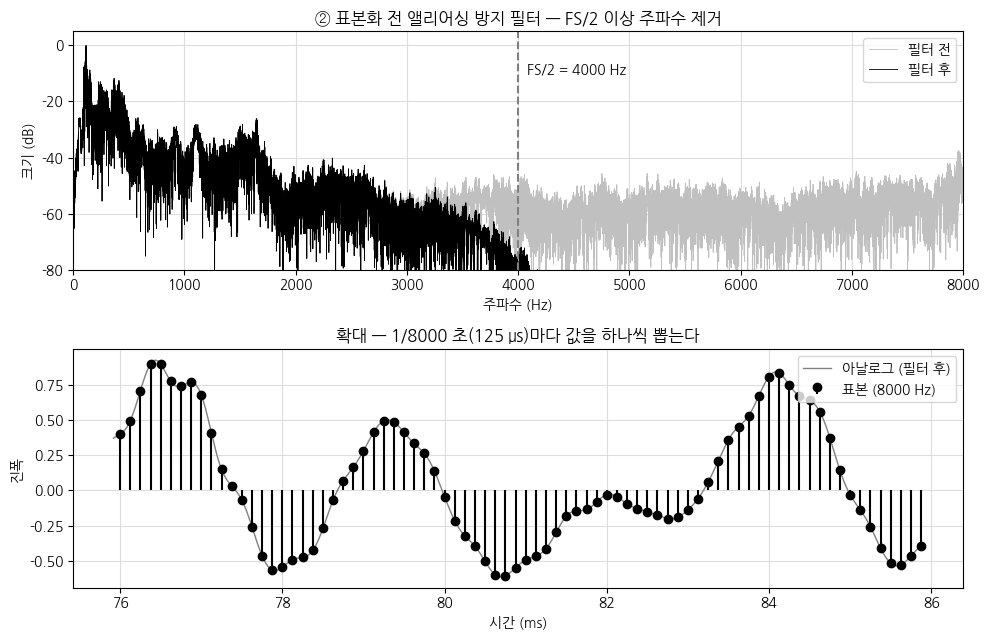

[소리 재생] 표본화된 소리 (8000 Hz)


In [5]:
FS = 8000          # 표본화 주파수 (Hz) — 바꿔 보세요: 4000, 16000
CUTOFF = 3400      # 앨리어싱 방지 필터 차단 주파수 (FS/2 보다 작아야 함)

sos = signal.butter(8, CUTOFF, fs=FS_ANALOG, output="sos")
x_f = signal.sosfiltfilt(sos, x)                     # 1) 앨리어싱 방지 필터
t_s = np.arange(0, len(x) / FS_ANALOG, 1 / FS)       # 2) 1/FS 초 간격의 표본 시각
x_s = np.interp(t_s, t, x_f)                         # 3) 그 시각의 값을 뽑음

print(f"표본화 주파수 {FS:,} Hz → 표본 간격 {1e6 / FS:.0f} μs, 표본 수 {len(x_s):,}개")
print(f"원 신호 표본 {len(x):,}개 → {len(x_s):,}개 ({len(x) / len(x_s):.1f}배 감소)")

fig, ax = plt.subplots(2, 1, figsize=(10, 6.5))
f, X = spectrum(x, FS_ANALOG); ax[0].plot(f, X, color="silver", lw=0.6, label="필터 전")
f, X = spectrum(x_f, FS_ANALOG); ax[0].plot(f, X, color="black", lw=0.6, label="필터 후")
ax[0].axvline(FS / 2, ls="--", color="gray"); ax[0].text(FS / 2 + 80, -10, f"FS/2 = {FS // 2} Hz")
ax[0].set(title="② 표본화 전 앨리어싱 방지 필터 — FS/2 이상 주파수 제거", xlabel="주파수 (Hz)", ylabel="크기 (dB)",
          xlim=(0, 8000), ylim=(-80, 5))
ax[0].legend()

m = (t_s >= t[z0]) & (t_s < t[z1])
ax[1].plot(t[z0:z1] * 1000, x_f[z0:z1], color="gray", lw=1, label="아날로그 (필터 후)")
ax[1].stem(t_s[m] * 1000, x_s[m], linefmt="k-", markerfmt="ko", basefmt=" ", label=f"표본 ({FS} Hz)")
ax[1].set(title=f"확대 — 1/{FS} 초({1e6 / FS:.0f} μs)마다 값을 하나씩 뽑는다", xlabel="시간 (ms)", ylabel="진폭")
ax[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

play(x_s, FS, f"표본화된 소리 ({FS} Hz)")

### 실험 — 앨리어싱(Aliasing) 듣기
표본화 주파수를 **2,000 Hz** 로 크게 낮춰, 필터 없이 표본화한 소리와 필터를 거친 소리를 비교합니다.
필터 없이 표본화하면 높은 주파수 성분이 낮은 주파수로 **접혀 들어와(앨리어싱)** 소리가 거칠게 일그러집니다.

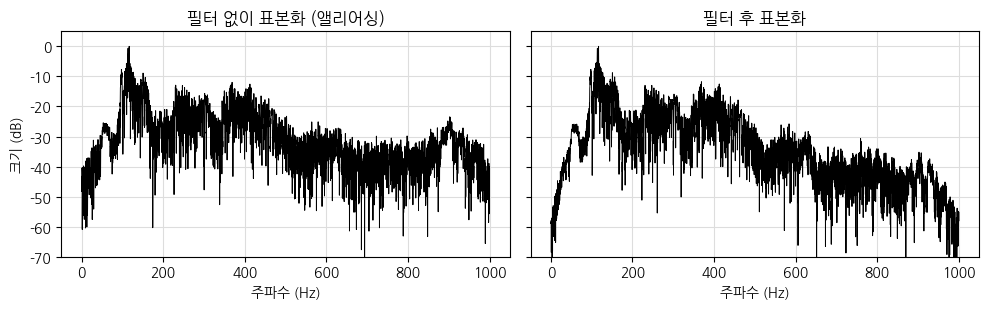

[소리 재생] 2 kHz 표본화 — 필터 없음 (앨리어싱)


[소리 재생] 2 kHz 표본화 — 필터 있음


In [6]:
FS_LOW = 2000
t_low = np.arange(0, len(x) / FS_ANALOG, 1 / FS_LOW)
alias = np.interp(t_low, t, x)                                                    # 필터 없음
clean = np.interp(t_low, t, signal.sosfiltfilt(signal.butter(8, 900, fs=FS_ANALOG, output="sos"), x))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for a, sig, name in [(ax[0], alias, "필터 없이 표본화 (앨리어싱)"), (ax[1], clean, "필터 후 표본화")]:
    f, X = spectrum(sig, FS_LOW); a.plot(f, X, lw=0.7)
    a.set(title=name, xlabel="주파수 (Hz)", ylim=(-70, 5))
ax[0].set_ylabel("크기 (dB)")
plt.tight_layout()
plt.show()

play(alias, FS_LOW, "2 kHz 표본화 — 필터 없음 (앨리어싱)")
play(clean, FS_LOW, "2 kHz 표본화 — 필터 있음")

## ③ 양자화 (Quantization)

표본값은 아직 소수점이 무한한 실수입니다. 이것을 **2<sup>n</sup> 개의 단계** 중 가장 가까운 값으로 반올림합니다.

- 비트 수 `n` 이 1 늘면 단계 수는 2배, 단계 간격 Δ 는 절반이 됩니다.
- 반올림하면서 생기는 오차를 **양자화 잡음** 이라 하고, 크기는 항상 **±Δ/2 이내** 입니다.
- 이론적 신호 대 양자화 잡음비 : **SQNR ≈ 6.02 n + 1.76 dB** (최대 크기 사인파 기준) — 비트 1개당 약 6 dB 개선

8비트 → 256단계, 단계 간격 Δ = 0.00781
SQNR: 3비트 2.2 dB / 8비트 34.4 dB


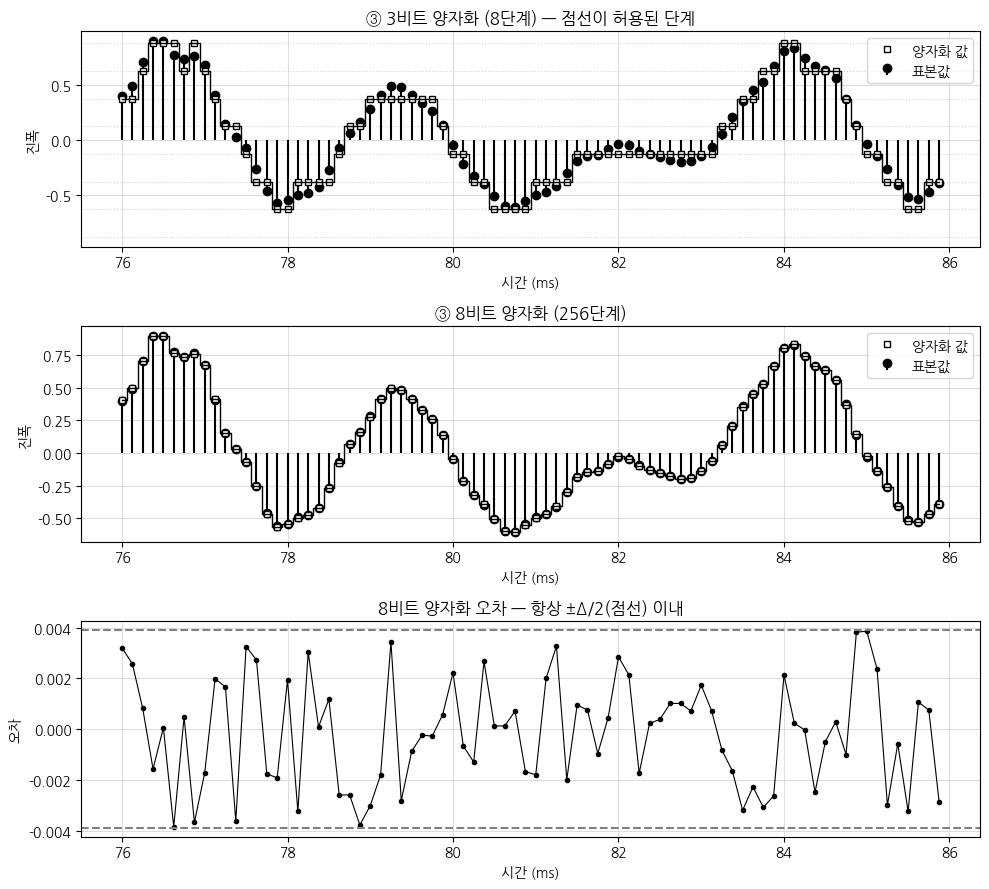

[소리 재생] 3비트 양자화


[소리 재생] 8비트 양자화


In [7]:
N_BITS = 8         # 양자화 비트 수 — 바꿔 보세요: 3, 4, 6, 12

def quantize(v, n_bits):
    """[-1, 1] 범위를 2^n 단계로 균일 양자화 → (단계 번호, 양자화된 값)"""
    L = 2 ** n_bits
    delta = 2 / L
    idx = np.clip(np.floor((v + 1) / delta), 0, L - 1).astype(int)
    return idx, -1 + (idx + 0.5) * delta

def sqnr_db(ref, q):
    return 10 * np.log10(np.sum(ref ** 2) / np.sum((ref - q) ** 2))

idx, x_q = quantize(x_s, N_BITS)
idx3, x_q3 = quantize(x_s, 3)
delta = 2 / 2 ** N_BITS
print(f"{N_BITS}비트 → {2 ** N_BITS}단계, 단계 간격 Δ = {delta:.5f}")
print(f"SQNR: 3비트 {sqnr_db(x_s, x_q3):.1f} dB / {N_BITS}비트 {sqnr_db(x_s, x_q):.1f} dB")

fig, ax = plt.subplots(3, 1, figsize=(10, 9))
for a, q, n in [(ax[0], x_q3, 3), (ax[1], x_q, N_BITS)]:
    if n <= 4:
        for lv in -1 + (np.arange(2 ** n) + 0.5) * (2 / 2 ** n):
            a.axhline(lv, color="lightgray", ls=":", lw=0.8)
    a.stem(t_s[m] * 1000, x_s[m], linefmt="-", markerfmt="o", basefmt=" ", label="표본값")
    a.plot(t_s[m] * 1000, q[m], "s", color="black", ms=5, mfc="white", label="양자화 값")
    a.step(t_s[m] * 1000, q[m], where="mid", color="black", lw=1)
    a.set(title=f"③ {n}비트 양자화 ({2 ** n}단계)" + (" — 점선이 허용된 단계" if n <= 4 else ""),
          xlabel="시간 (ms)", ylabel="진폭")
    a.legend(loc="upper right")

err = x_q - x_s
ax[2].plot(t_s[m] * 1000, err[m], "o-", ms=3, lw=0.8)
for s in (-1, 1):
    ax[2].axhline(s * delta / 2, color="gray", ls="--")
ax[2].set(title=f"{N_BITS}비트 양자화 오차 — 항상 ±Δ/2(점선) 이내", xlabel="시간 (ms)", ylabel="오차")
plt.tight_layout()
plt.show()

play(x_q3, FS, "3비트 양자화")
play(x_q, FS, f"{N_BITS}비트 양자화")

### 비트 수에 따른 음질(SQNR) 변화
실제 음성은 대부분 작은 소리라서 이론값보다 SQNR 이 낮게 나오지만, **비트당 약 6 dB** 씩 좋아지는 경향은 같습니다.

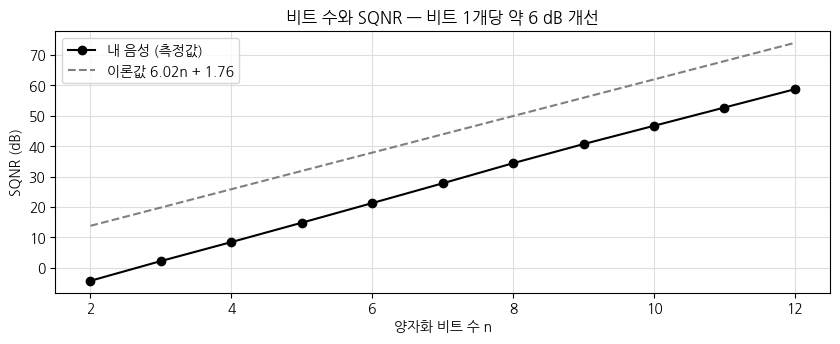

In [8]:
bit_list = np.arange(2, 13)
measured = [sqnr_db(x_s, quantize(x_s, n)[1]) for n in bit_list]

plt.figure(figsize=(10, 3.4))
plt.plot(bit_list, measured, "o-", label="내 음성 (측정값)")
plt.plot(bit_list, 6.02 * bit_list + 1.76, "--", color="gray", label="이론값 6.02n + 1.76")
plt.title("비트 수와 SQNR — 비트 1개당 약 6 dB 개선")
plt.xlabel("양자화 비트 수 n"); plt.ylabel("SQNR (dB)"); plt.legend()
plt.show()

## ④ 부호화 (Encoding)
양자화 단계 번호를 `N_BITS` 자리의 **2진 부호(코드워드)** 로 바꿔 한 줄로 이어 붙이면 디지털 비트열이 됩니다.

> 비트율(bit rate) = 표본화 주파수 × 비트 수 — 전화 음성(8 kHz × 8 bit) 은 **64 kbps** 입니다.

   시간(ms)       표본값    단계 번호     양자화 값   부호(2진)
   76.000    0.3991      179    0.4023   10110011
   76.125    0.4935      191    0.4961   10111111
   76.250    0.7062      218    0.7070   11011010
   76.375    0.8961      242    0.8945   11110010
   76.500    0.8945      242    0.8945   11110010
   76.625    0.7734      226    0.7695   11100010
   76.750    0.7378      222    0.7383   11011110
   76.875    0.7654      225    0.7617   11100001

비트율 = 8,000 Hz × 8 bit = 64 kbps
전체 비트 수 = 256,000 bit (31.2 KB)


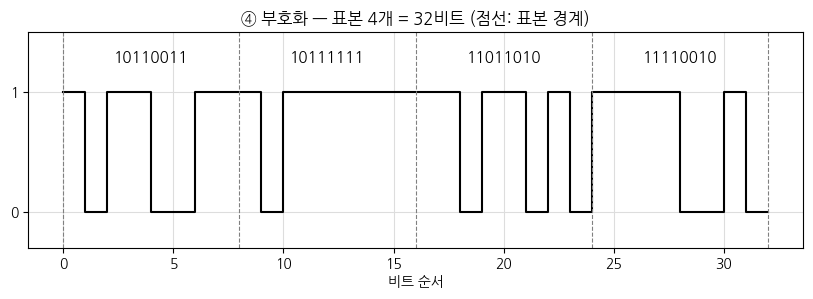

In [9]:
codes = [format(i, f"0{N_BITS}b") for i in idx]
bits = ((idx[:, None] >> np.arange(N_BITS - 1, -1, -1)) & 1).astype(np.uint8).ravel()

k0 = int(np.argmax(m))   # 확대 구간의 첫 표본부터
print(f"{'시간(ms)':>9} {'표본값':>9} {'단계 번호':>8} {'양자화 값':>9}   부호(2진)")
for k in range(k0, k0 + 8):
    print(f"{t_s[k] * 1000:9.3f} {x_s[k]:9.4f} {idx[k]:8d} {x_q[k]:9.4f}   {codes[k]}")

print(f"\n비트율 = {FS:,} Hz × {N_BITS} bit = {FS * N_BITS / 1000:.0f} kbps")
print(f"전체 비트 수 = {len(bits):,} bit ({len(bits) / 8 / 1024:.1f} KB)")

n_show = 4
seg = bits[k0 * N_BITS:(k0 + n_show) * N_BITS]
tb = np.arange(len(seg) + 1)
plt.figure(figsize=(10, 2.8))
plt.step(tb, np.append(seg, seg[-1]), where="post", lw=1.5)
for j in range(n_show + 1):
    plt.axvline(j * N_BITS, color="gray", ls="--", lw=0.8)
for j in range(n_show):
    plt.text(j * N_BITS + N_BITS / 2, 1.25, codes[k0 + j], ha="center", fontsize=11)
plt.ylim(-0.3, 1.5); plt.yticks([0, 1])
plt.title(f"④ 부호화 — 표본 {n_show}개 = {n_show * N_BITS}비트 (점선: 표본 경계)")
plt.xlabel("비트 순서")
plt.show()

---
# Part B. 디지털 전송 — 보호(암호화)하고 보내고 받기

## ⑤ 암호화 (Encryption)
비트열을 그대로 보내면 중간에서 가로챈 사람도 소리를 복원할 수 있습니다.
여기서는 **비밀 키로 만든 난수 비트열(키 스트림)** 과 **XOR** 하는 **스트림 암호** 방식으로 비트열을 보호합니다.

| 평문 비트 | 키 스트림 | XOR 결과 (암호문) |
|---|---|---|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

- 같은 키 스트림으로 **한 번 더 XOR** 하면 원래 비트가 돌아옵니다. (A ⊕ K ⊕ K = A)
- 실습용 원리 설명이며, 실제 서비스에서는 AES, ChaCha20 같은 검증된 암호 알고리즘을 사용합니다.

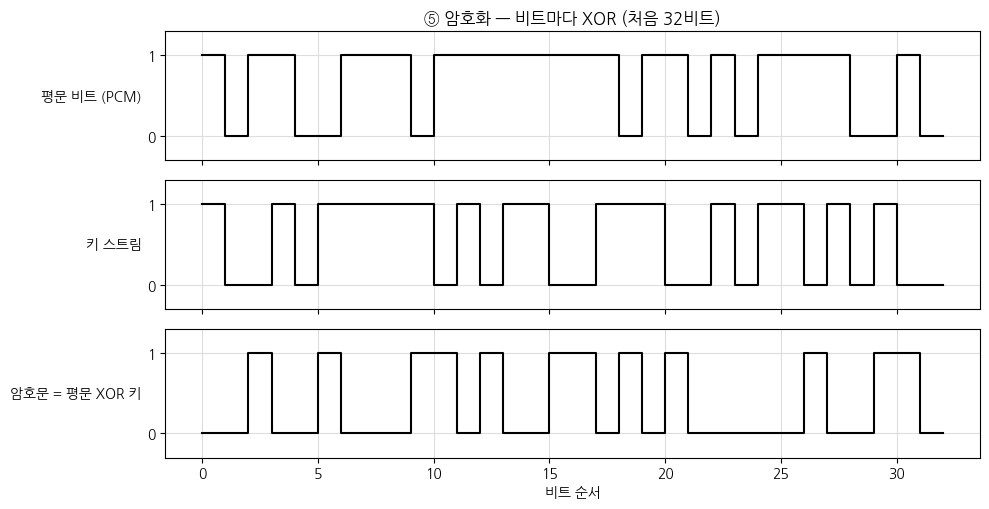

[소리 재생] 도청자가 암호문을 그대로 소리로 바꾸면?


In [10]:
ENCRYPT = True               # False 로 바꾸면 암호화 없이 전송
KEY = "my-secret-key"        # 송신자와 수신자만 아는 비밀 키

def keystream(key, n):
    """비밀 키로부터 같은 난수 비트열을 재현"""
    seed = int(hashlib.sha256(key.encode()).hexdigest(), 16) % 2 ** 32
    return np.random.default_rng(seed).integers(0, 2, n, dtype=np.uint8)

ks = keystream(KEY, len(bits))
tx_bits = bits ^ ks if ENCRYPT else bits.copy()

def bits_to_idx(b, n_bits):
    return (b.reshape(-1, n_bits).astype(int) * (1 << np.arange(n_bits - 1, -1, -1))).sum(axis=1)

def dequantize(i, n_bits):
    return -1 + (i + 0.5) * (2 / 2 ** n_bits)

s0, s1 = k0 * N_BITS, k0 * N_BITS + 32
fig, ax = plt.subplots(3, 1, figsize=(10, 5.2), sharex=True)
for a, b, name in [(ax[0], bits, "평문 비트 (PCM)"), (ax[1], ks, "키 스트림"), (ax[2], tx_bits, "암호문 = 평문 XOR 키")]:
    seg = b[s0:s1]
    a.step(np.arange(33), np.append(seg, seg[-1]), where="post", lw=1.5)
    a.set_ylim(-0.3, 1.3); a.set_yticks([0, 1]); a.set_ylabel(name, rotation=0, ha="right", va="center")
ax[0].set_title("⑤ 암호화 — 비트마다 XOR (처음 32비트)")
ax[2].set_xlabel("비트 순서")
plt.tight_layout()
plt.show()

play(dequantize(bits_to_idx(tx_bits, N_BITS), N_BITS), FS, "도청자가 암호문을 그대로 소리로 바꾸면?")

## ⑥ 선로 부호화와 전송 채널
비트를 전선이나 전파로 보내려면 **전압 파형** 으로 바꿔야 합니다. 여기서는 **극성 NRZ** 방식을 씁니다.

- 1 → **+1 V**, 0 → **−1 V** 를 비트 하나 동안 유지 (비트당 `SPB` 개 표본)
- 전송 중에 채널이 **잡음(AWGN, 백색 가우시안 잡음)** 을 더합니다. 잡음 크기는 `SNR_DB`(신호 대 잡음비)로 정합니다.

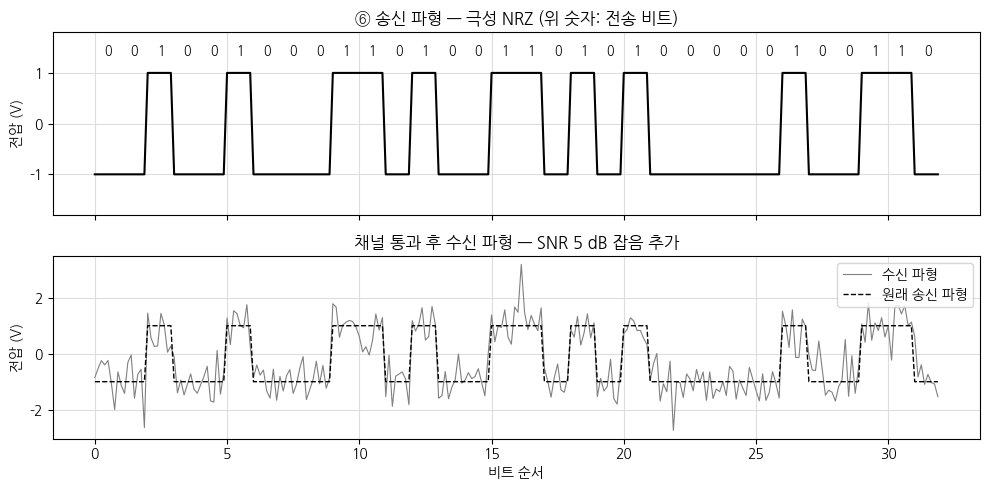

In [11]:
SPB = 8            # 비트 하나를 표현하는 파형 표본 수
SNR_DB = 5         # 채널 SNR (dB) — 낮출수록 잡음이 커짐: 0, -5, -8

def line_code(b, spb):
    """극성 NRZ: 1 → +1, 0 → -1"""
    return np.repeat(2.0 * b - 1.0, spb)

def channel(wave, snr_db, seed=0):
    """AWGN 채널: SNR 에 맞는 가우시안 잡음을 더함"""
    sigma = np.sqrt(np.mean(wave ** 2) / 10 ** (snr_db / 10))
    return wave + np.random.default_rng(seed).normal(0, sigma, len(wave))

tx_wave = line_code(tx_bits, SPB)
rx_wave = channel(tx_wave, SNR_DB)

w0, w1 = s0 * SPB, s1 * SPB
tw = np.arange(w1 - w0) / SPB
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(tw, tx_wave[w0:w1], lw=1.5)
for j, b in enumerate(tx_bits[s0:s1]):
    ax[0].text(j + 0.5, 1.35, str(b), ha="center", fontsize=9)
ax[0].set(title="⑥ 송신 파형 — 극성 NRZ (위 숫자: 전송 비트)", ylabel="전압 (V)", ylim=(-1.8, 1.8))
ax[1].plot(tw, rx_wave[w0:w1], color="gray", lw=0.8, label="수신 파형")
ax[1].plot(tw, tx_wave[w0:w1], color="black", lw=1, ls="--", label="원래 송신 파형")
ax[1].set(title=f"채널 통과 후 수신 파형 — SNR {SNR_DB} dB 잡음 추가", xlabel="비트 순서", ylabel="전압 (V)")
ax[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

## ⑦ 수신 — 비트 판정
수신기는 비트 하나 구간의 표본 `SPB` 개를 **평균** 내어(잡음을 줄이는 효과) **0 V 보다 크면 1, 작으면 0** 으로 판정합니다.
잡음이 너무 커서 반대쪽으로 넘어가면 **비트 오류** 가 생기고, 그 비율을 **BER(Bit Error Rate)** 라고 합니다.

전송 비트 256,000개 중 오류 0개 → BER = 0.00e+00


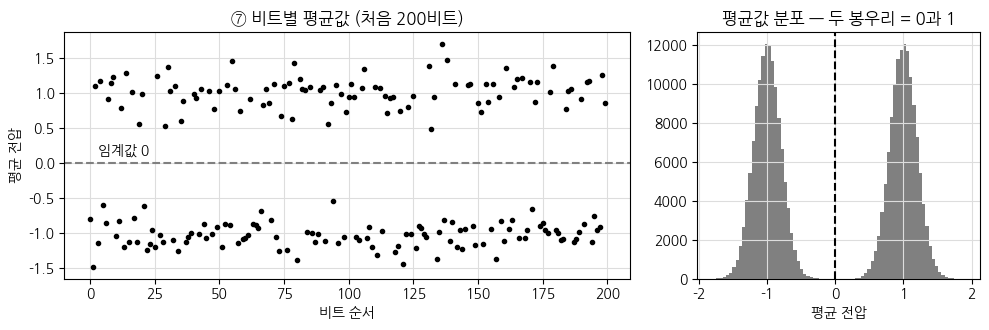

In [12]:
def detect(rx, spb):
    z = rx.reshape(-1, spb).mean(axis=1)    # 비트 구간 평균
    return z, (z > 0).astype(np.uint8)      # 임계값 0 으로 판정

z, rx_bits = detect(rx_wave, SPB)
n_err = int(np.sum(rx_bits != tx_bits))
print(f"전송 비트 {len(tx_bits):,}개 중 오류 {n_err:,}개 → BER = {n_err / len(tx_bits):.2e}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [2, 1]})
ax[0].plot(np.arange(200), z[:200], "o", ms=3)
ax[0].axhline(0, color="gray", ls="--"); ax[0].text(3, 0.08, "임계값 0", va="bottom")
ax[0].set(title="⑦ 비트별 평균값 (처음 200비트)", xlabel="비트 순서", ylabel="평균 전압")
ax[1].hist(z, bins=80, color="gray")
ax[1].axvline(0, color="black", ls="--")
ax[1].set(title="평균값 분포 — 두 봉우리 = 0과 1", xlabel="평균 전압")
plt.tight_layout()
plt.show()

## ⑧ 복호화 — 암호 해제 + PCM 복호
1. 받은 비트열을 **같은 키 스트림으로 XOR** 해 암호를 풉니다.
2. `N_BITS` 개씩 끊어 2진 부호 → **단계 번호** → **양자화 값** 으로 되돌립니다.

키가 틀리면 어떻게 되는지도 함께 확인합니다.

     받은 부호    단계 번호      복원 값   (송신 부호)
    10110011      179    0.4023   (10110011)
    10111111      191    0.4961   (10111111)
    11011010      218    0.7070   (11011010)
    11110010      242    0.8945   (11110010)
    11110010      242    0.8945   (11110010)
    11100010      226    0.7695   (11100010)


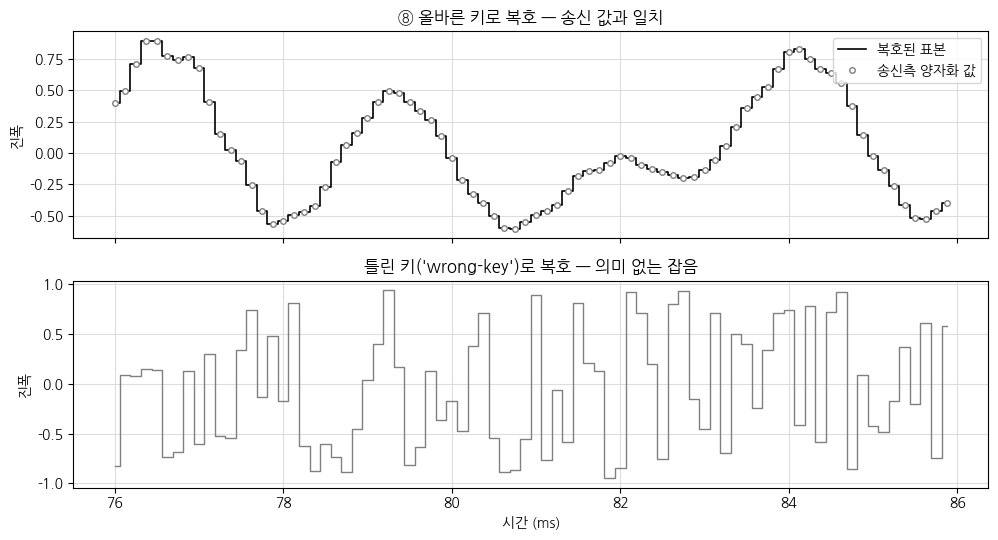

[소리 재생] 틀린 키로 복호한 소리


In [13]:
WRONG_KEY = "wrong-key"

dec_bits = rx_bits ^ keystream(KEY, len(rx_bits)) if ENCRYPT else rx_bits
idx_rx = bits_to_idx(dec_bits, N_BITS)
y_s = dequantize(idx_rx, N_BITS)                                  # 올바른 키로 복호

bad_bits = rx_bits ^ keystream(WRONG_KEY, len(rx_bits)) if ENCRYPT else rx_bits
y_bad = dequantize(bits_to_idx(bad_bits, N_BITS), N_BITS)         # 틀린 키로 복호

rx_codes = ["".join(map(str, dec_bits[k * N_BITS:(k + 1) * N_BITS])) for k in range(k0, k0 + 6)]
print(f"{'받은 부호':>10} {'단계 번호':>8} {'복원 값':>9}   (송신 부호)")
for j, k in enumerate(range(k0, k0 + 6)):
    print(f"{rx_codes[j]:>12} {idx_rx[k]:8d} {y_s[k]:9.4f}   ({codes[k]})")

fig, ax = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
ax[0].step(t_s[m] * 1000, y_s[m], where="mid", lw=1.2, label="복호된 표본")
ax[0].plot(t_s[m] * 1000, x_q[m], "o", ms=4, mfc="white", color="gray", label="송신측 양자화 값")
ax[0].set(title="⑧ 올바른 키로 복호 — 송신 값과 일치", ylabel="진폭"); ax[0].legend(loc="upper right")
ax[1].step(t_s[m] * 1000, y_bad[m], where="mid", lw=1, color="gray")
ax[1].set(title=f"틀린 키('{WRONG_KEY}')로 복호 — 의미 없는 잡음", xlabel="시간 (ms)", ylabel="진폭")
plt.tight_layout()
plt.show()

play(y_bad, FS, "틀린 키로 복호한 소리")

## ⑨ D/A 변환 — 소리로 복원
디지털 표본을 다시 연속 파형으로 만드는 두 단계입니다.
1. **0차 홀드(ZOH)** : 다음 표본이 올 때까지 값을 유지 → 계단 모양 파형
2. **복원 필터(LPF)** : 계단의 날카로운 모서리(고주파)를 깎아 매끄러운 파형으로 만듦

복원 음질: 원 신호(필터 후) 대비 SNR = 33.7 dB


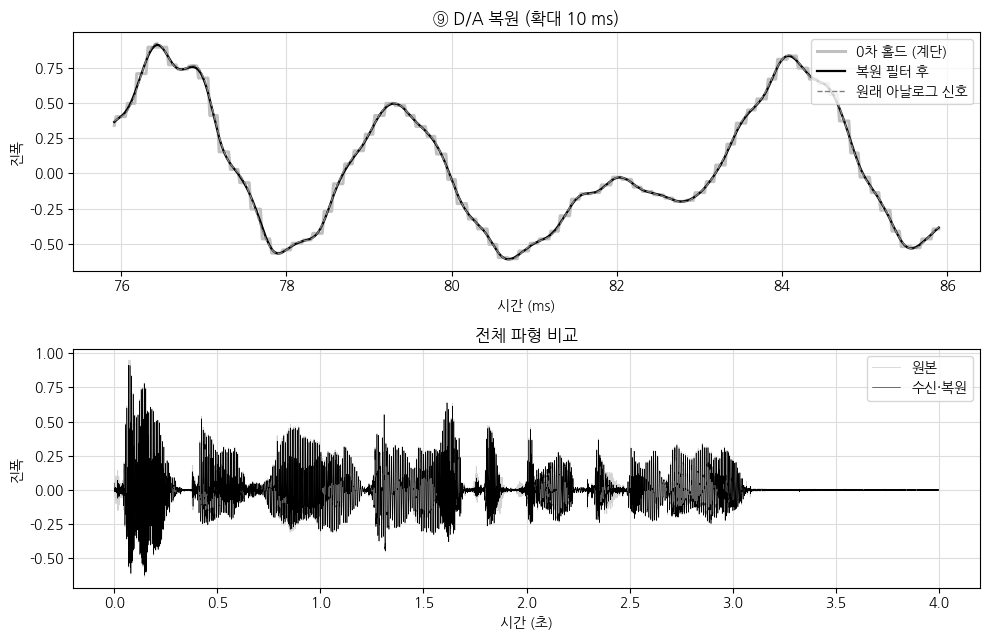

[소리 재생] 원본 음성


[소리 재생] 전송 후 복원된 음성 (8000 Hz, 8비트, SNR 5 dB)


In [14]:
hold = np.clip(np.round(t * FS).astype(int), 0, len(y_s) - 1)   # 표본 시각을 중심으로 유지 (홀드 지연 보정)
y_zoh = y_s[hold]                                     # 1) 0차 홀드
y_rec = signal.sosfiltfilt(sos, y_zoh)                # 2) 복원 필터 (차단 주파수 CUTOFF)

def snr_db(ref, y):
    return 10 * np.log10(np.sum(ref ** 2) / np.sum((ref - y) ** 2))

print(f"복원 음질: 원 신호(필터 후) 대비 SNR = {snr_db(x_f, y_rec):.1f} dB")

fig, ax = plt.subplots(2, 1, figsize=(10, 6.5))
tz = t[z0:z1] * 1000
ax[0].plot(tz, y_zoh[z0:z1], color="silver", lw=2.2, label="0차 홀드 (계단)")
ax[0].plot(tz, y_rec[z0:z1], color="black", lw=1.6, label="복원 필터 후")
ax[0].plot(tz, x_f[z0:z1], color="gray", lw=1, ls="--", label="원래 아날로그 신호")
ax[0].set(title="⑨ D/A 복원 (확대 10 ms)", xlabel="시간 (ms)", ylabel="진폭"); ax[0].legend(loc="upper right")
ax[1].plot(t, x, color="lightgray", lw=0.6, label="원본")
ax[1].plot(t, y_rec, color="black", lw=0.4, label="수신·복원")
ax[1].set(title="전체 파형 비교", xlabel="시간 (초)", ylabel="진폭"); ax[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

play(x, FS_ANALOG, "원본 음성")
play(y_rec, FS_ANALOG, f"전송 후 복원된 음성 ({FS} Hz, {N_BITS}비트, SNR {SNR_DB} dB)")

---
# Part C. 실험 — 채널 잡음이 소리에 미치는 영향

## 잡음(SNR)과 비트 오류율(BER)
SNR 을 바꿔 가며 BER 을 측정하고 이론값과 비교합니다.
극성 NRZ + 구간 평균 수신기의 이론 BER 은 **½ · erfc( √(SPB · SNR / 2) )** 입니다.

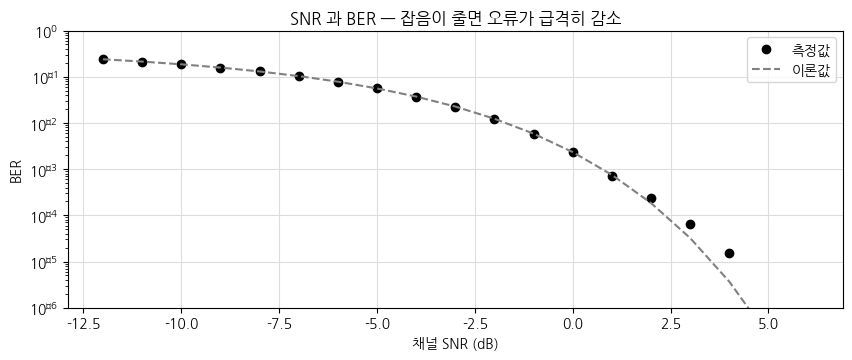

In [15]:
snr_list = np.arange(-12, 7, 1)
sim, theory = [], []
test_bits = tx_bits[:200_000]
for s in snr_list:
    _, rb = detect(channel(line_code(test_bits, SPB), s, seed=1), SPB)
    sim.append(np.mean(rb != test_bits))
    theory.append(0.5 * erfc(np.sqrt(SPB * 10 ** (s / 10) / 2)))

plt.figure(figsize=(10, 3.6))
plt.semilogy(snr_list, sim, "o", label="측정값")
plt.semilogy(snr_list, theory, "--", color="gray", label="이론값")
plt.title("SNR 과 BER — 잡음이 줄면 오류가 급격히 감소")
plt.xlabel("채널 SNR (dB)"); plt.ylabel("BER"); plt.ylim(1e-6, 1); plt.legend()
plt.show()

## 잡음별로 복원된 소리 듣기
디지털 전송은 잡음이 어느 수준 이하면 **완벽히 복원** 되다가, 넘어서면 **'틱틱' 하는 클릭 잡음** 이 생깁니다.
상위 비트(MSB)가 틀리면 값이 크게 튀기 때문입니다. — 아날로그 전송처럼 서서히 나빠지지 않는 것이 디지털의 특징입니다.

In [16]:
def pcm_link(snr_db_, key=KEY):
    """양자화된 비트열을 암호화 → 전송 → 판정 → 복호 → 복원까지 한 번에"""
    ks_ = keystream(key, len(bits))
    sent = bits ^ ks_ if ENCRYPT else bits
    _, got = detect(channel(line_code(sent, SPB), snr_db_, seed=2), SPB)
    plain = got ^ ks_ if ENCRYPT else got
    ys = dequantize(bits_to_idx(plain, N_BITS), N_BITS)
    y = signal.sosfiltfilt(sos, ys[np.clip(np.round(t * FS).astype(int), 0, len(ys) - 1)])
    return y, np.mean(got != sent)

for s in [6, -2, -5, -8]:
    y, ber = pcm_link(s)
    play(y, FS_ANALOG, f"SNR {s:+d} dB → BER {ber:.1e}")

[소리 재생] SNR +6 dB → BER 0.0e+00


[소리 재생] SNR -2 dB → BER 1.2e-02


[소리 재생] SNR -5 dB → BER 5.5e-02


[소리 재생] SNR -8 dB → BER 1.3e-01


---
# 해 보기

설정값을 바꾸고 **런타임 → 모두 실행** 으로 다시 실행하며 아래 질문에 답해 보세요.

1. `N_BITS` 를 **3, 4, 6, 12** 로 바꿔 들어 보세요. 몇 비트부터 원음과 구별하기 어려운가요? 비트율은 각각 얼마인가요?
2. `FS` 를 **4000** (이때 `CUTOFF = 1800`), **16000** (이때 `CUTOFF = 7000`) 으로 바꿔 보세요. 목소리가 어떻게 달라지나요? 나이퀴스트 정리로 설명해 보세요.
3. `SNR_DB` 를 낮춰 가며 말소리를 알아듣기 어려워지는 SNR 을 찾아보세요. 이때 BER 은 얼마인가요?
4. `ENCRYPT = False` 로 바꾸면 도청자가 듣는 소리는 어떻게 되나요? 암호화가 필요한 이유를 정리해 보세요.
5. `SPB` 를 **2** 와 **16** 으로 바꾸면 같은 SNR 에서 BER 이 어떻게 달라지나요? 대신 무엇을 손해 보나요?
6. CD 음질(44.1 kHz, 16비트, 스테레오) 1분짜리 음악의 PCM 데이터 크기를 계산해 보세요.

### 정리
| 단계 | 핵심 |
|---|---|
| 표본화 | 최고 주파수의 2배 이상으로 — 부족하면 앨리어싱 |
| 양자화 | 비트 1개당 SQNR 약 6 dB — 비트가 적으면 거친 잡음 |
| 부호화 | 비트율 = FS × N_BITS |
| 암호화 | 키 스트림 XOR — 키가 없으면 잡음으로만 들림 |
| 전송·판정 | 잡음이 크면 비트 오류(BER) 증가 → 클릭 잡음 |
| D/A 복원 | 0차 홀드 + 복원 필터로 매끄러운 소리 |